Import thư viện và đọc dữ liệu:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/airline_clean.csv")

# %% Thống kê delay theo satisfaction
delay_summary = df.groupby("satisfaction")[[
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]].agg(["count", "mean", "median", "std", "max"])

print(delay_summary.round(2))

                        Departure Delay in Minutes                             \
                                             count   mean median    std   max   
satisfaction                                                                    
neutral or dissatisfied                      73452  16.41    0.0  40.18  1592   
satisfied                                    56428  12.51    0.0  35.01  1305   

                        Arrival Delay in Minutes                               
                                           count   mean median    std     max  
satisfaction                                                                   
neutral or dissatisfied                    73225  17.06    0.0  40.52  1584.0  
satisfied                                  56262  12.53    0.0  35.45  1280.0  


Boxplot Arrival Delay theo satisfaction

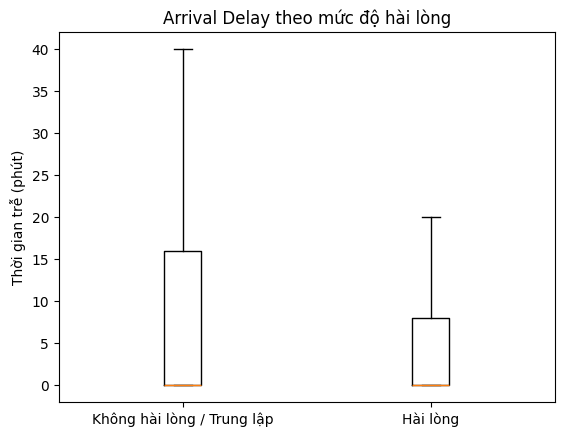

In [2]:
arrival = df.dropna(subset=["Arrival Delay in Minutes"])

sat_arrival = arrival[
    arrival["satisfaction"] == "satisfied"
]["Arrival Delay in Minutes"]

not_sat_arrival = arrival[
    arrival["satisfaction"] == "neutral or dissatisfied"
]["Arrival Delay in Minutes"]

plt.boxplot(
    [not_sat_arrival, sat_arrival],
    tick_labels=["Không hài lòng / Trung lập", "Hài lòng"],
    showfliers=False
)
plt.title("Arrival Delay theo mức độ hài lòng")
plt.ylabel("Thời gian trễ (phút)")
plt.show()


Histogram Arrival Delay

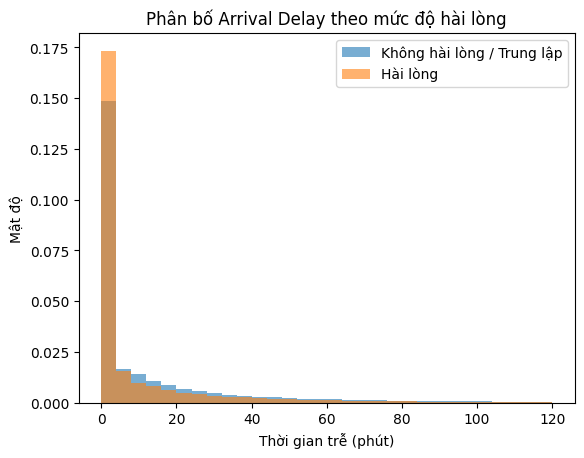

In [3]:
plot_data = arrival[arrival["Arrival Delay in Minutes"] <= 120]

plt.hist(
    plot_data[
        plot_data["satisfaction"] == "neutral or dissatisfied"
    ]["Arrival Delay in Minutes"],
    bins=30,
    alpha=0.6,
    label="Không hài lòng / Trung lập",
    density=True
)

plt.hist(
    plot_data[
        plot_data["satisfaction"] == "satisfied"
    ]["Arrival Delay in Minutes"],
    bins=30,
    alpha=0.6,
    label="Hài lòng",
    density=True
)

plt.title("Phân bố Arrival Delay theo mức độ hài lòng")
plt.xlabel("Thời gian trễ (phút)")
plt.ylabel("Mật độ")
plt.legend()
plt.show()